<div style="width: 100%; overflow: hidden;">
    <div style="width: 150px; float: left;"> <img src="data/D4Sci_logo_ball.png" alt="Data For Science, Inc" align="left" border="0"> </div>
    <div style="float: left; margin-left: 10px;"> <h1>Harness Engineering</h1>
<h1>03 - Context Within a Token Budget</h1>
        <p>Bruno Gonçalves<br/>
        <a href="http://www.data4sci.com/">www.data4sci.com</a><br/>
            @bgoncalves, @data4sci</p></div>
</div>

In [1]:
from collections import Counter
from pprint import pprint
from pathlib import Path
import json

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import duckdb

import watermark

from harness.mcp_client import MCPClient
from harness.llm import MockAnalyst, estimate_tokens
from harness.agent import Agent, ToolBox, DEFAULT_SYSTEM_PROMPT
from harness.workshop import load, restore
from harness.exercises import show_run, check_03, long_transcript

%load_ext watermark
%matplotlib inline

We start by print out the versions of the libraries we're using for future reference

In [2]:
%watermark -n -v -m -g -iv

Python implementation: CPython
Python version       : 3.13.13
IPython version      : 9.17.1

Compiler    : Clang 22.1.3 
OS          : Darwin
Release     : 25.6.0
Machine     : arm64
Processor   : arm
CPU cores   : 16
Architecture: 64bit

Git hash: f45998e2cfd5a6dc68ecdc40a669ed274dd25212

duckdb    : 1.5.6
json      : 2.0.9
matplotlib: 3.11.2
numpy     : 2.5.4
pandas    : 3.1.0
watermark : 2.6.0



Load default figure style

In [3]:
plt.style.use('d4sci.mplstyle')
colors = plt.rcParams['axes.prop_cycle'].by_key()['color']

# Context is a budget

Everything the model knows during a run sits in its context window: the system prompt, the question, every tool call and every result. That window is finite, and every token in it costs money, latency and attention. Models get worse at finding the important fact as the context fills with unimportant ones.

Context engineering means deciding **what the model sees**:

- **Compact result summaries** instead of raw rows
- **Expandable handles** so nothing is lost, just kept out of the context until needed
- **Conversation compaction** when a session grows long
- **Tiered memory** so durable facts don't have to be rediscovered every run

**You are building `harness/context.py` in this notebook.** Cells that start with `%%writefile` write the module one section at a time (`-a` appends), and the cells after them import what was just written. Run them in order. A finished copy is in `reference/context.py`; if something goes wrong, `restore("context")` puts it back.

# 1. How big is a tool result?

We'll estimate tokens as `characters / 4`. That's crude, but good enough for budgeting, and it needs no tokenizer download.

In [4]:
client = MCPClient().start()

queries = {
    "one number": "SELECT COUNT(*) FROM orders",
    "monthly revenue": "SELECT strftime(order_date, '%Y-%m') AS m, SUM(amount_cents) FROM orders GROUP BY 1",
    "August feedback": "SELECT * FROM customer_feedback WHERE created_at BETWEEN DATE '2026-08-01' AND DATE '2026-08-31'",
    "all orders": "SELECT * FROM orders",
}
results = {name: client.call_tool("execute_query", {"sql": sql}) for name, sql in queries.items()}
sizes = pd.Series({name: estimate_tokens(r.text) for name, r in results.items()})
sizes

one number            39
monthly revenue      142
August feedback    13323
all orders         22888
dtype: int64

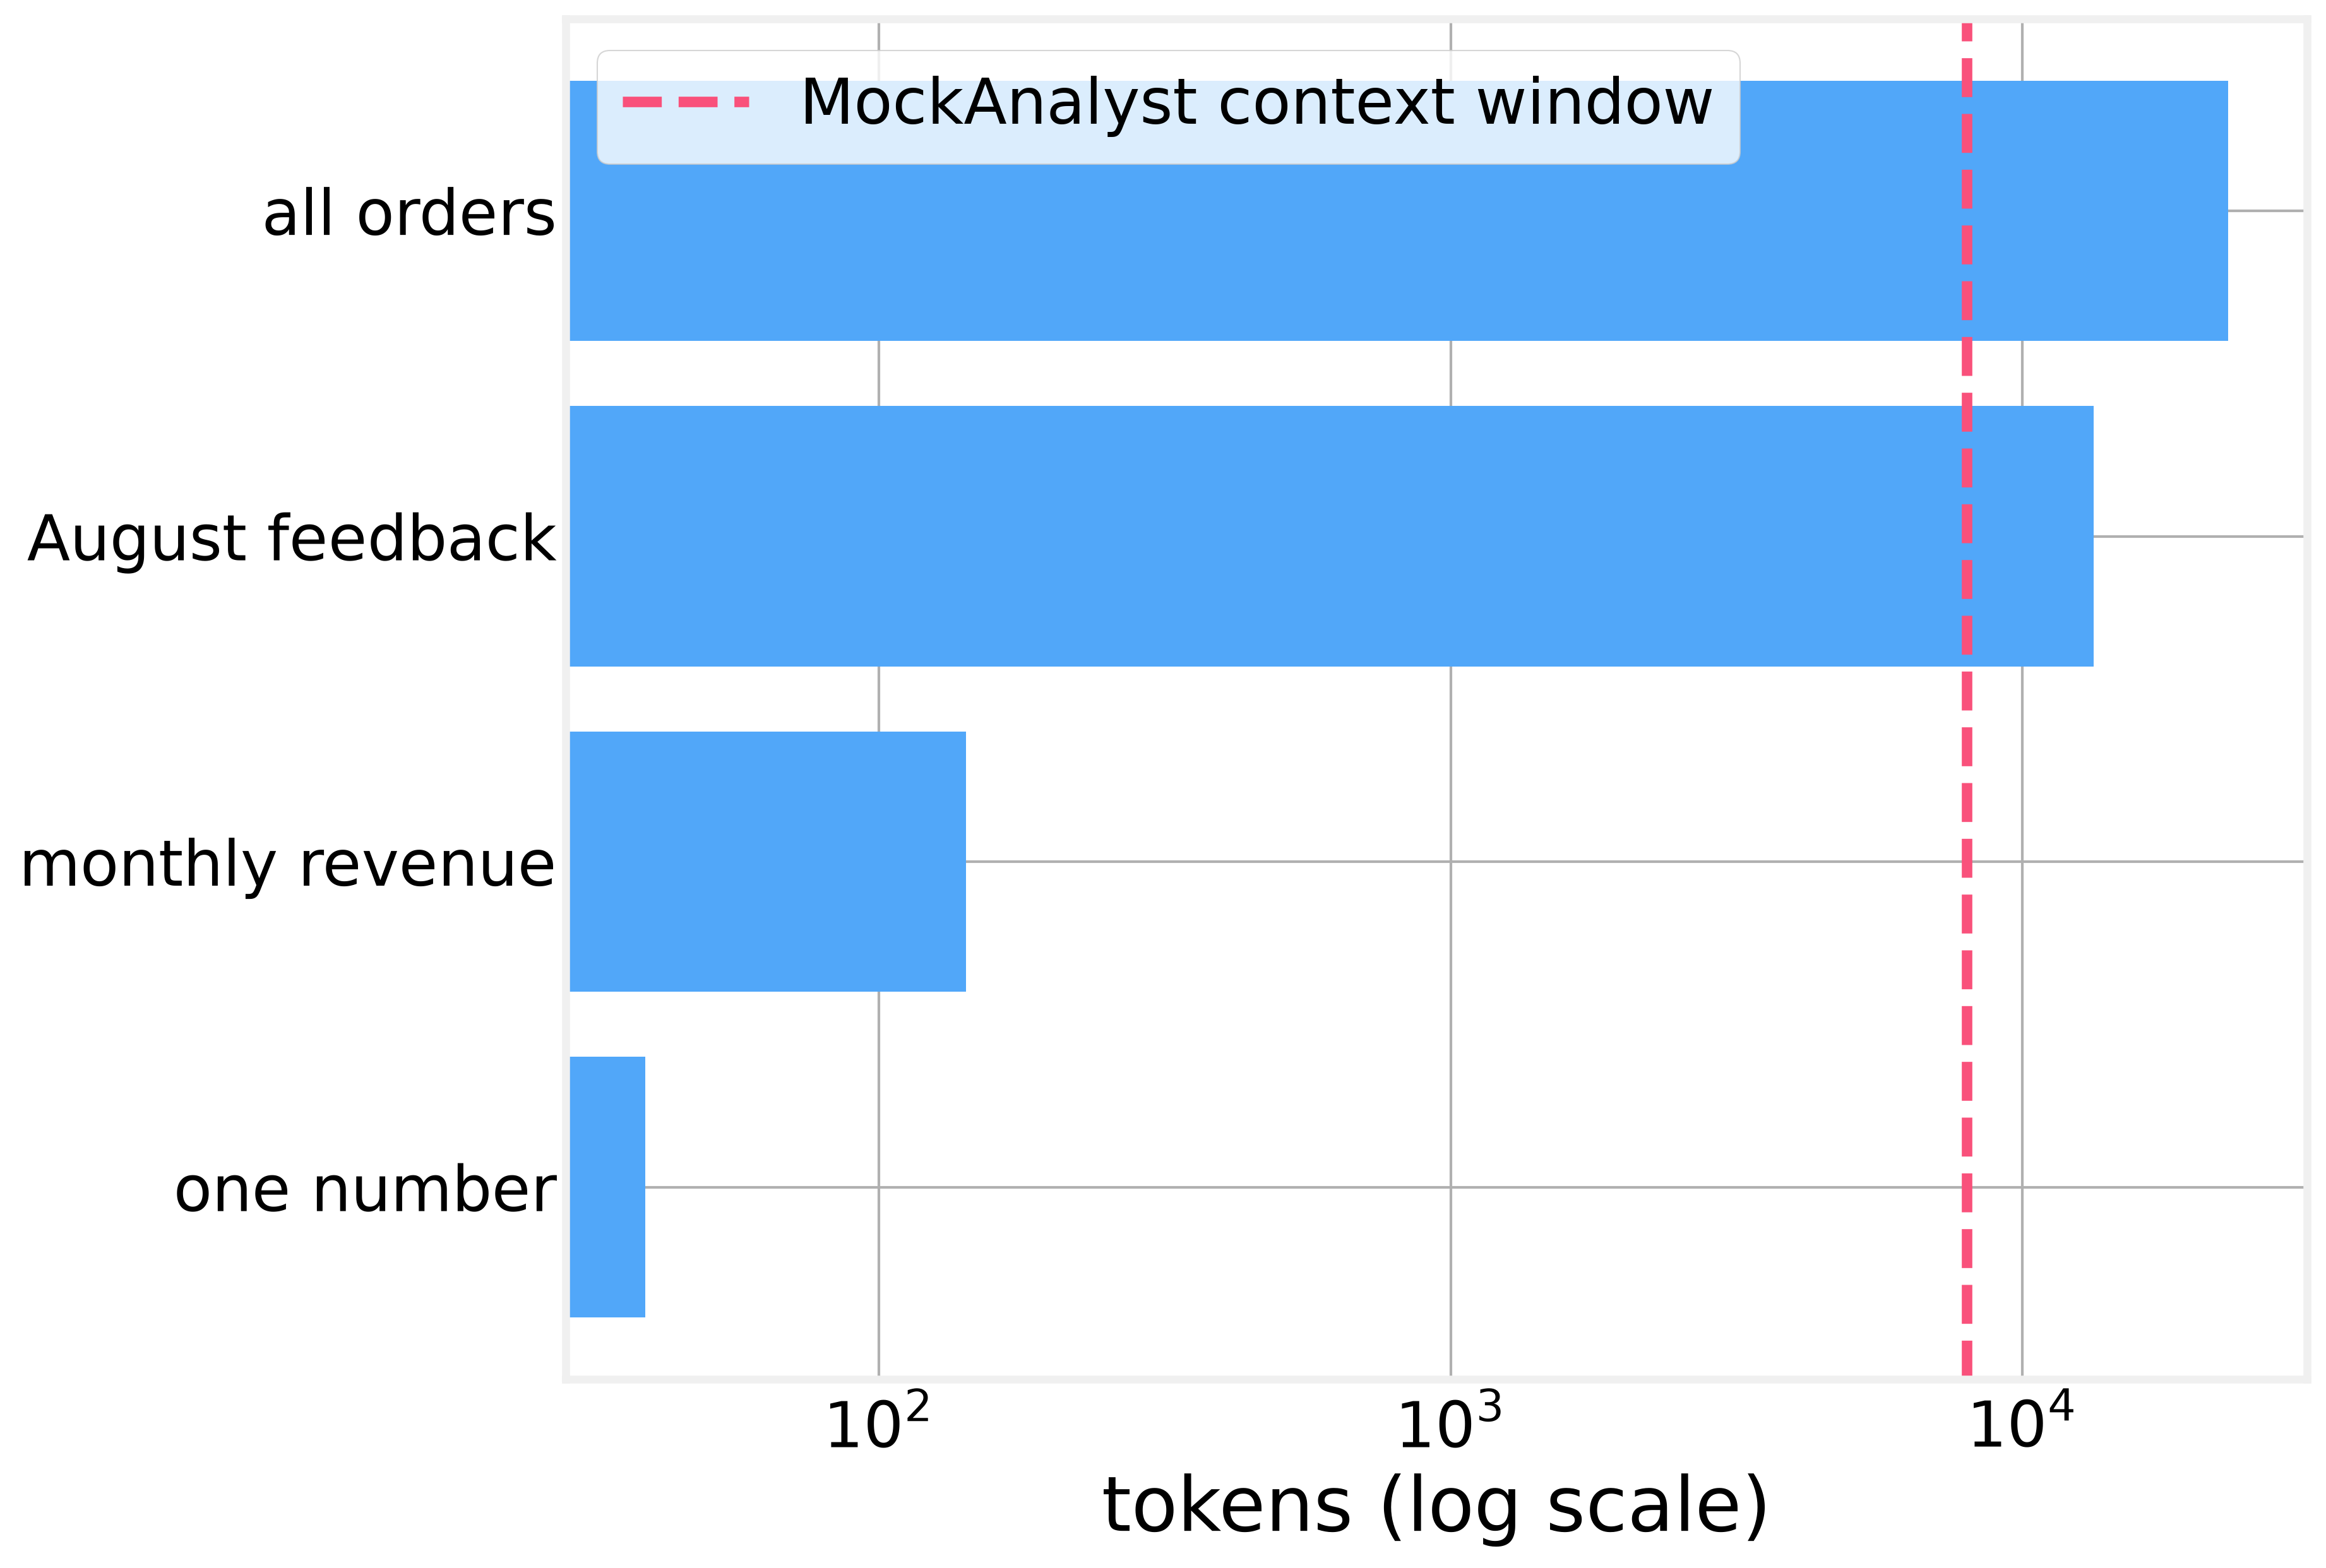

In [5]:
fig, ax = plt.subplots()
ax.barh(sizes.index, sizes.values, color=colors[0])
ax.axvline(8_000, color=colors[5], linestyle="--", label="MockAnalyst context window")
ax.set_xscale("log")
ax.set_xlabel("tokens (log scale)")
ax.legend();

One careless `SELECT *` is enough to blow the context window on its own.

# 2. The truncation trap

The DuckDB server protects itself by capping results at about 50 KB. Look at *how* it does that:

In [6]:
data = results["all orders"].data
print("rowCount: ", data["rowCount"])
print("truncated:", data.get("truncated"))
print("warning:  ", data.get("warning"))
print("true count:", client.call_tool("execute_query", {"sql": "SELECT COUNT(*) AS n FROM orders"}).data["rows"][0][0])

rowCount:  673
truncated: True
true count: 28551


`rowCount` reports the rows *returned*, not the rows that exist. A model that reads `"rowCount": 673` will confidently report 673 orders. Server-side truncation keeps the context small and silently makes the data wrong. Our summaries have to say so loudly.

# 3. Compact summaries

A good summary of a query result has:

- its **shape** (rows, columns, types)
- a **profile** of each column (range, distinct values, typical length)
- a **few example rows**, with long cells clipped
- an explicit **warning** when the data is truncated
- a **handle** pointing to the full result

The module starts with exactly that: a profile per column and a summary per result.

In [7]:
%%writefile harness/context.py
"""Context management: keep the model inside a token budget without losing facts.

Four tools for one job:

``summarize_result``  turn a big query result into a compact, honest summary
``ResultStore``       keep the full result outside the context, behind a handle
``ContextCompactor``  shrink the conversation when it grows past a budget
``MemoryStore``       tiered memory: durable facts recalled into the prompt
"""

from __future__ import annotations

import json
import re
from dataclasses import dataclass, field
from pathlib import Path

from .agent import ToolBox
from .llm import ToolCall, count_message_tokens, estimate_tokens
from .mcp_client import ToolResult


# --- compact result summaries ----------------------------------------------------------


def _is_num(x) -> bool:
    if isinstance(x, bool):
        return False
    if isinstance(x, (int, float)):
        return True
    try:
        float(x)
        return isinstance(x, str) and bool(re.fullmatch(r"-?\d+(\.\d+)?", x))
    except (TypeError, ValueError):
        return False


def column_profile(name: str, ctype: str, values: list) -> dict:
    vals = [v for v in values if v is not None]
    prof = {"name": name, "type": ctype, "nulls": len(values) - len(vals)}
    if not vals:
        return prof
    if all(_is_num(v) for v in vals):
        nums = [float(v) for v in vals]
        prof.update(min=min(nums), max=max(nums), mean=round(sum(nums) / len(nums), 2))
    else:
        strs = [str(v) for v in vals]
        distinct = sorted(set(strs))
        prof["distinct"] = len(distinct)
        if len(distinct) <= 8:
            prof["values"] = distinct
        elif max(map(len, strs)) <= 12:
            prof.update(min=min(strs), max=max(strs))
        else:
            prof["avg_length"] = round(sum(map(len, strs)) / len(strs))
    return prof


def summarize_result(data: dict, handle: str, preview_rows: int = 3,
                     max_cell: int = 80) -> dict:
    """Compact stand-in for a query result: shape, column profiles, a few rows."""
    cols, rows = data.get("columns", []), data.get("rows", [])
    types = data.get("columnTypes", ["?"] * len(cols))
    clip = lambda v: v[:max_cell] + "..." if isinstance(v, str) and len(v) > max_cell else v
    summary = {
        "handle": handle,
        "row_count": len(rows),
        "columns": [column_profile(c, t, [r[i] for r in rows])
                    for i, (c, t) in enumerate(zip(cols, types))],
        "preview": [[clip(v) for v in r] for r in rows[:preview_rows]],
        "note": f"Full result stored as {handle!r}; call expand_result to page through it. "
                "Prefer aggregating in SQL over reading rows.",
    }
    if data.get("truncated"):
        summary["truncated"] = True
        summary["note"] = ("WARNING: the server truncated this result, so row_count is NOT "
                           "the true total. Use COUNT(*)/aggregates in SQL. " + summary["note"])
    return summary

Overwriting harness/context.py


In [8]:
load("context")
from harness.context import summarize_result

feedback = results["August feedback"].data
summary = summarize_result(feedback, handle="r1")

print(json.dumps(summary, indent=1, default=str)[:2500])

{
 "handle": "r1",
 "row_count": 230,
 "columns": [
  {
   "name": "feedback_id",
   "type": "BIGINT",
   "nulls": 0,
   "min": 1711.0,
   "max": 2045.0,
   "mean": 1825.96
  },
  {
   "name": "customer_id",
   "type": "BIGINT",
   "nulls": 0,
   "min": 2.0,
   "max": 1987.0,
   "mean": 923.92
  },
  {
   "name": "created_at",
   "type": "DATE",
   "nulls": 0,
   "distinct": 31,
   "min": "2026-08-01",
   "max": "2026-08-31"
  },
  {
   "name": "channel",
   "type": "VARCHAR",
   "nulls": 0,
   "distinct": 3,
   "values": [
    "mobile",
    "retail",
    "web"
   ]
  },
  {
   "name": "rating",
   "type": "BIGINT",
   "nulls": 0,
   "min": 1.0,
   "max": 5.0,
   "mean": 3.13
  },
  {
   "name": "comment",
   "type": "VARCHAR",
   "nulls": 0,
   "distinct": 190,
   "avg_length": 142
  }
 ],
 "preview": [
  [
   1711,
   365,
   "2026-08-01",
   "mobile",
   4,
   "Fast delivery and the Daypack 20L fits perfectly. I have been a customer for a f..."
  ],
  [
   1712,
   1321,
   "2026-08

In [9]:
raw_tokens = estimate_tokens(results["August feedback"].text)
summary_tokens = estimate_tokens(json.dumps(summary, default=str))
print(f"raw: {raw_tokens:,} tokens   summary: {summary_tokens:,} tokens   ({raw_tokens / summary_tokens:.0f}x smaller)")

raw: 13,323 tokens   summary: 278 tokens   (48x smaller)


In [10]:
print(json.dumps(summarize_result(results["all orders"].data, "r2")["note"]))

"WARNING: the server truncated this result, so row_count is NOT the true total. Use COUNT(*)/aggregates in SQL. Full result stored as 'r2'; call expand_result to page through it. Prefer aggregating in SQL over reading rows."


# 4. Handles: nothing lost, nothing loaded

The full result goes into a `ResultStore`, outside the context. The model gets a short handle (`r1`) and an `expand_result` tool to page through the result when it really needs rows. Pages are capped by both row count and size.

In [11]:
%%writefile -a harness/context.py


# --- handles: keep full results out of the context --------------------------------------

class ResultStore:
    """Full results live here, out of the context window, behind short handles."""

    def __init__(self):
        self.results: dict[str, dict] = {}

    def put(self, data: dict) -> str:
        handle = f"r{len(self.results) + 1}"
        self.results[handle] = data
        return handle

    def page(self, handle: str, offset: int = 0, limit: int = 10,
             max_chars: int = 3000) -> dict:
        if handle not in self.results:
            return {"error": f"unknown handle {handle!r}"}
        data = self.results[handle]
        rows, out = data["rows"][offset:offset + limit], []
        for r in rows:  # stop early rather than blow the budget
            if len(json.dumps(out + [r], default=str)) > max_chars:
                break
            out.append(r)
        return {"handle": handle, "columns": data["columns"], "offset": offset,
                "rows": out, "returned": len(out), "total": len(data["rows"]),
                "next_offset": offset + len(out) if offset + len(out) < len(data["rows"]) else None}

    def register_tool(self, toolbox: ToolBox) -> None:
        def expand(args: dict) -> ToolResult:
            page = self.page(args["handle"], int(args.get("offset", 0)),
                             min(int(args.get("limit", 10)), 50))
            return ToolResult(ok="error" not in page, text=json.dumps(page, default=str),
                              data=page)
        toolbox.add("expand_result",
                    "Page through a stored query result by handle (max 50 rows per call).",
                    {"type": "object", "additionalProperties": False, "required": ["handle"],
                     "properties": {"handle": {"type": "string"},
                                    "offset": {"type": "integer"},
                                    "limit": {"type": "integer"}}},
                    expand, readOnlyHint=True)

Appending to harness/context.py


In [12]:
load("context")
from harness.context import ResultStore

store = ResultStore()
handle = store.put(feedback)
page = store.page(handle, offset=0, limit=3)
print(json.dumps(page, indent=1, default=str)[:1200])

{
 "handle": "r1",
 "columns": [
  "feedback_id",
  "customer_id",
  "created_at",
  "channel",
  "rating",
  "comment"
 ],
 "offset": 0,
 "rows": [
  [
   1711,
   365,
   "2026-08-01",
   "mobile",
   4,
   "Fast delivery and the Daypack 20L fits perfectly. I have been a customer for a few years and usually recommend you to friends from my hiking club, so I hope this feedback is useful to the team."
  ],
  [
   1712,
   1321,
   "2026-08-01",
   "web",
   4,
   "Customer service helped me pick the right size of Socks 3-pack."
  ],
  [
   1713,
   1646,
   "2026-08-01",
   "mobile",
   5,
   "The Approach Shoe is lighter than I expected, very happy."
  ]
 ],
 "returned": 3,
 "total": 230,
 "next_offset": 3
}


# 5. Wiring it in

`ResultCompactor` is an `after_tool` hook: any result over `max_chars` is swapped for its summary before the model sees it.

In [13]:
%%writefile -a harness/context.py


# --- wiring it in: an after_tool hook --------------------------------------------------

class ResultCompactor:
    """``after_tool`` hook: results over ``max_chars`` become summary + handle."""

    def __init__(self, store: ResultStore, max_chars: int = 1500):
        self.store = store
        self.max_chars = max_chars

    def __call__(self, call: ToolCall, result: ToolResult, content: str) -> str:
        data = result.data
        if not result.ok or not data or "rows" not in data or len(content) <= self.max_chars:
            return content
        handle = self.store.put(data)
        return json.dumps(summarize_result(data, handle), default=str)

Appending to harness/context.py


Same greedy model, same 8,000-token window as in notebook 01:

In [14]:
load("context")
from harness.context import ResultCompactor

FEEDBACK = "Summarize what customers said in their feedback in August."

toolbox = ToolBox(client)
store = ResultStore()
store.register_tool(toolbox)

agent = Agent(MockAnalyst(), toolbox, after_tool=[ResultCompactor(store, max_chars=1500)])
res = agent.run(FEEDBACK)
show_run(res)

[1] execute_query: SELECT * FROM customer_feedback WHERE created_at BETWEEN DATE '2026-08-01' AND DATE '2026-08-31'
    -> {"handle": "r1", "row_count": 230, "columns": [{"name": "feedback_id", "type": "BIGINT", "nulls": 0, "min": 17
[2] execute_query: SELECT COUNT(*) AS n, AVG(rating) AS avg_rating, AVG(CASE WHEN comment ILIKE '%checkout%' THEN 1 ELSE 0 END) A
    -> { "success": true, "columns": [ "n", "avg_rating", "share_checkout" ], "columnTypes": [ "BIGINT", "DOUBLE", "D
[3] execute_query: SELECT created_at, rating, comment FROM customer_feedback WHERE created_at BETWEEN DATE '2026-08-01' AND DATE 
    -> {"handle": "r2", "row_count": 10, "columns": [{"name": "created_at", "type": "DATE", "nulls": 0, "distinct": 7

status=completed  steps=4  tool_calls=3  input_tokens=4,176

In August we received 230 feedback comments with an average rating of 3.13. 23% of them mention checkout problems.


The run now completes. The model got a summary instead of 230 raw rows, saw the note to aggregate in SQL, and **changed its plan**: its next query computes the statistics in the database. Good context management doesn't just save tokens; it pushes the model toward better strategies.

A side effect worth noticing: the injected comment never reached the model this time. Summaries clip long cells, so the attack text didn't fit. That's luck, not a defense. A query that selects the comment directly would still deliver it, which is why notebook 04 adds real guardrails.

# 6. Conversation compaction

In a multi-turn session every model call re-sends the whole conversation, so input tokens grow with every step. `ContextCompactor` is a `prepare_context` hook that kicks in above a budget:

1. **Elide** old tool results; their handles still point to the data.
2. **Fold** the oldest exchanges into a one-paragraph summary.

The system prompt, the current question and the most recent messages are always kept. Tool calls and their results are never split, because real model APIs reject a result without its call.

In [15]:
%%writefile -a harness/context.py


# --- conversation compaction ------------------------------------------------------------

class ContextCompactor:
    """``prepare_context`` hook that keeps the prompt under ``budget`` tokens.

    Stage 1: elide the content of old tool results (keeps call/result pairing).
    Stage 2: fold the oldest exchanges into a single summary message.
    The system prompt, the question and the last ``keep_last`` messages are kept."""

    def __init__(self, budget: int = 4000, keep_last: int = 4):
        self.budget = budget
        self.keep_last = keep_last
        self.log: list[dict] = []

    def __call__(self, messages: list[dict]) -> list[dict]:
        before = count_message_tokens(messages)
        if before <= self.budget:
            return messages
        head, body = messages[:2], [dict(m) for m in messages[2:]]
        recent_start = max(0, len(body) - self.keep_last)
        users = [i for i, m in enumerate(body) if m["role"] == "user"]
        if users:  # never fold away the question currently being answered
            recent_start = min(recent_start, users[-1])
        # Stage 1: elide old tool outputs, oldest first.
        for m in body[:recent_start]:
            if count_message_tokens(head + body) <= self.budget:
                break
            if m["role"] == "tool" and not m["content"].startswith("[elided"):
                handle = re.search(r'"handle": "(r\d+)"', m["content"])
                m["content"] = (f"[elided {estimate_tokens(m['content'])} tokens"
                                + (f"; full result in {handle.group(1)}" if handle else "") + "]")
        # Stage 2: fold old exchanges into one summary message.
        if count_message_tokens(head + body) > self.budget and recent_start > 0:
            old, body = body[:recent_start], body[recent_start:]
            # never start the kept window on a tool result whose call was folded away
            while body and body[0]["role"] == "tool":
                old.append(body.pop(0))
            done = [f"{c['name']}({json.dumps(c['arguments'])[:120]})"
                    for m in old if m["role"] == "assistant" for c in m.get("tool_calls") or []]
            body = [{"role": "user", "content": "Summary of earlier steps: called "
                     + "; ".join(done) + ". Their results were elided to save context."}] + body
        out = head + body
        self.log.append({"before": before, "after": count_message_tokens(out)})
        return out

Appending to harness/context.py


In [16]:
load("context")
from harness.context import ContextCompactor

QUESTIONS = ["What was our monthly revenue in 2026?",
             "Why did revenue drop in August?",
             FEEDBACK,
             "What was EMEA revenue in July compared to June?"] * 2


class TokenLog:
    """A minimal tracer: records the input tokens of every model call."""
    def __init__(self):
        self.tokens = []

    def emit(self, kind, **fields):
        if kind == "llm_call":
            self.tokens.append(fields["input_tokens"])


def session(prepare_context=None):
    log = TokenLog()
    agent = Agent(MockAnalyst.careful(context_window=100_000), toolbox,
                  after_tool=[ResultCompactor(store)], prepare_context=prepare_context, tracer=log)
    history = None
    for q in QUESTIONS:
        res = agent.run(q, history=history)
        history = res.messages
    return log.tokens, res

plain, _ = session()
compactor = ContextCompactor(budget=1500, keep_last=4)
compacted, last = session(compactor)

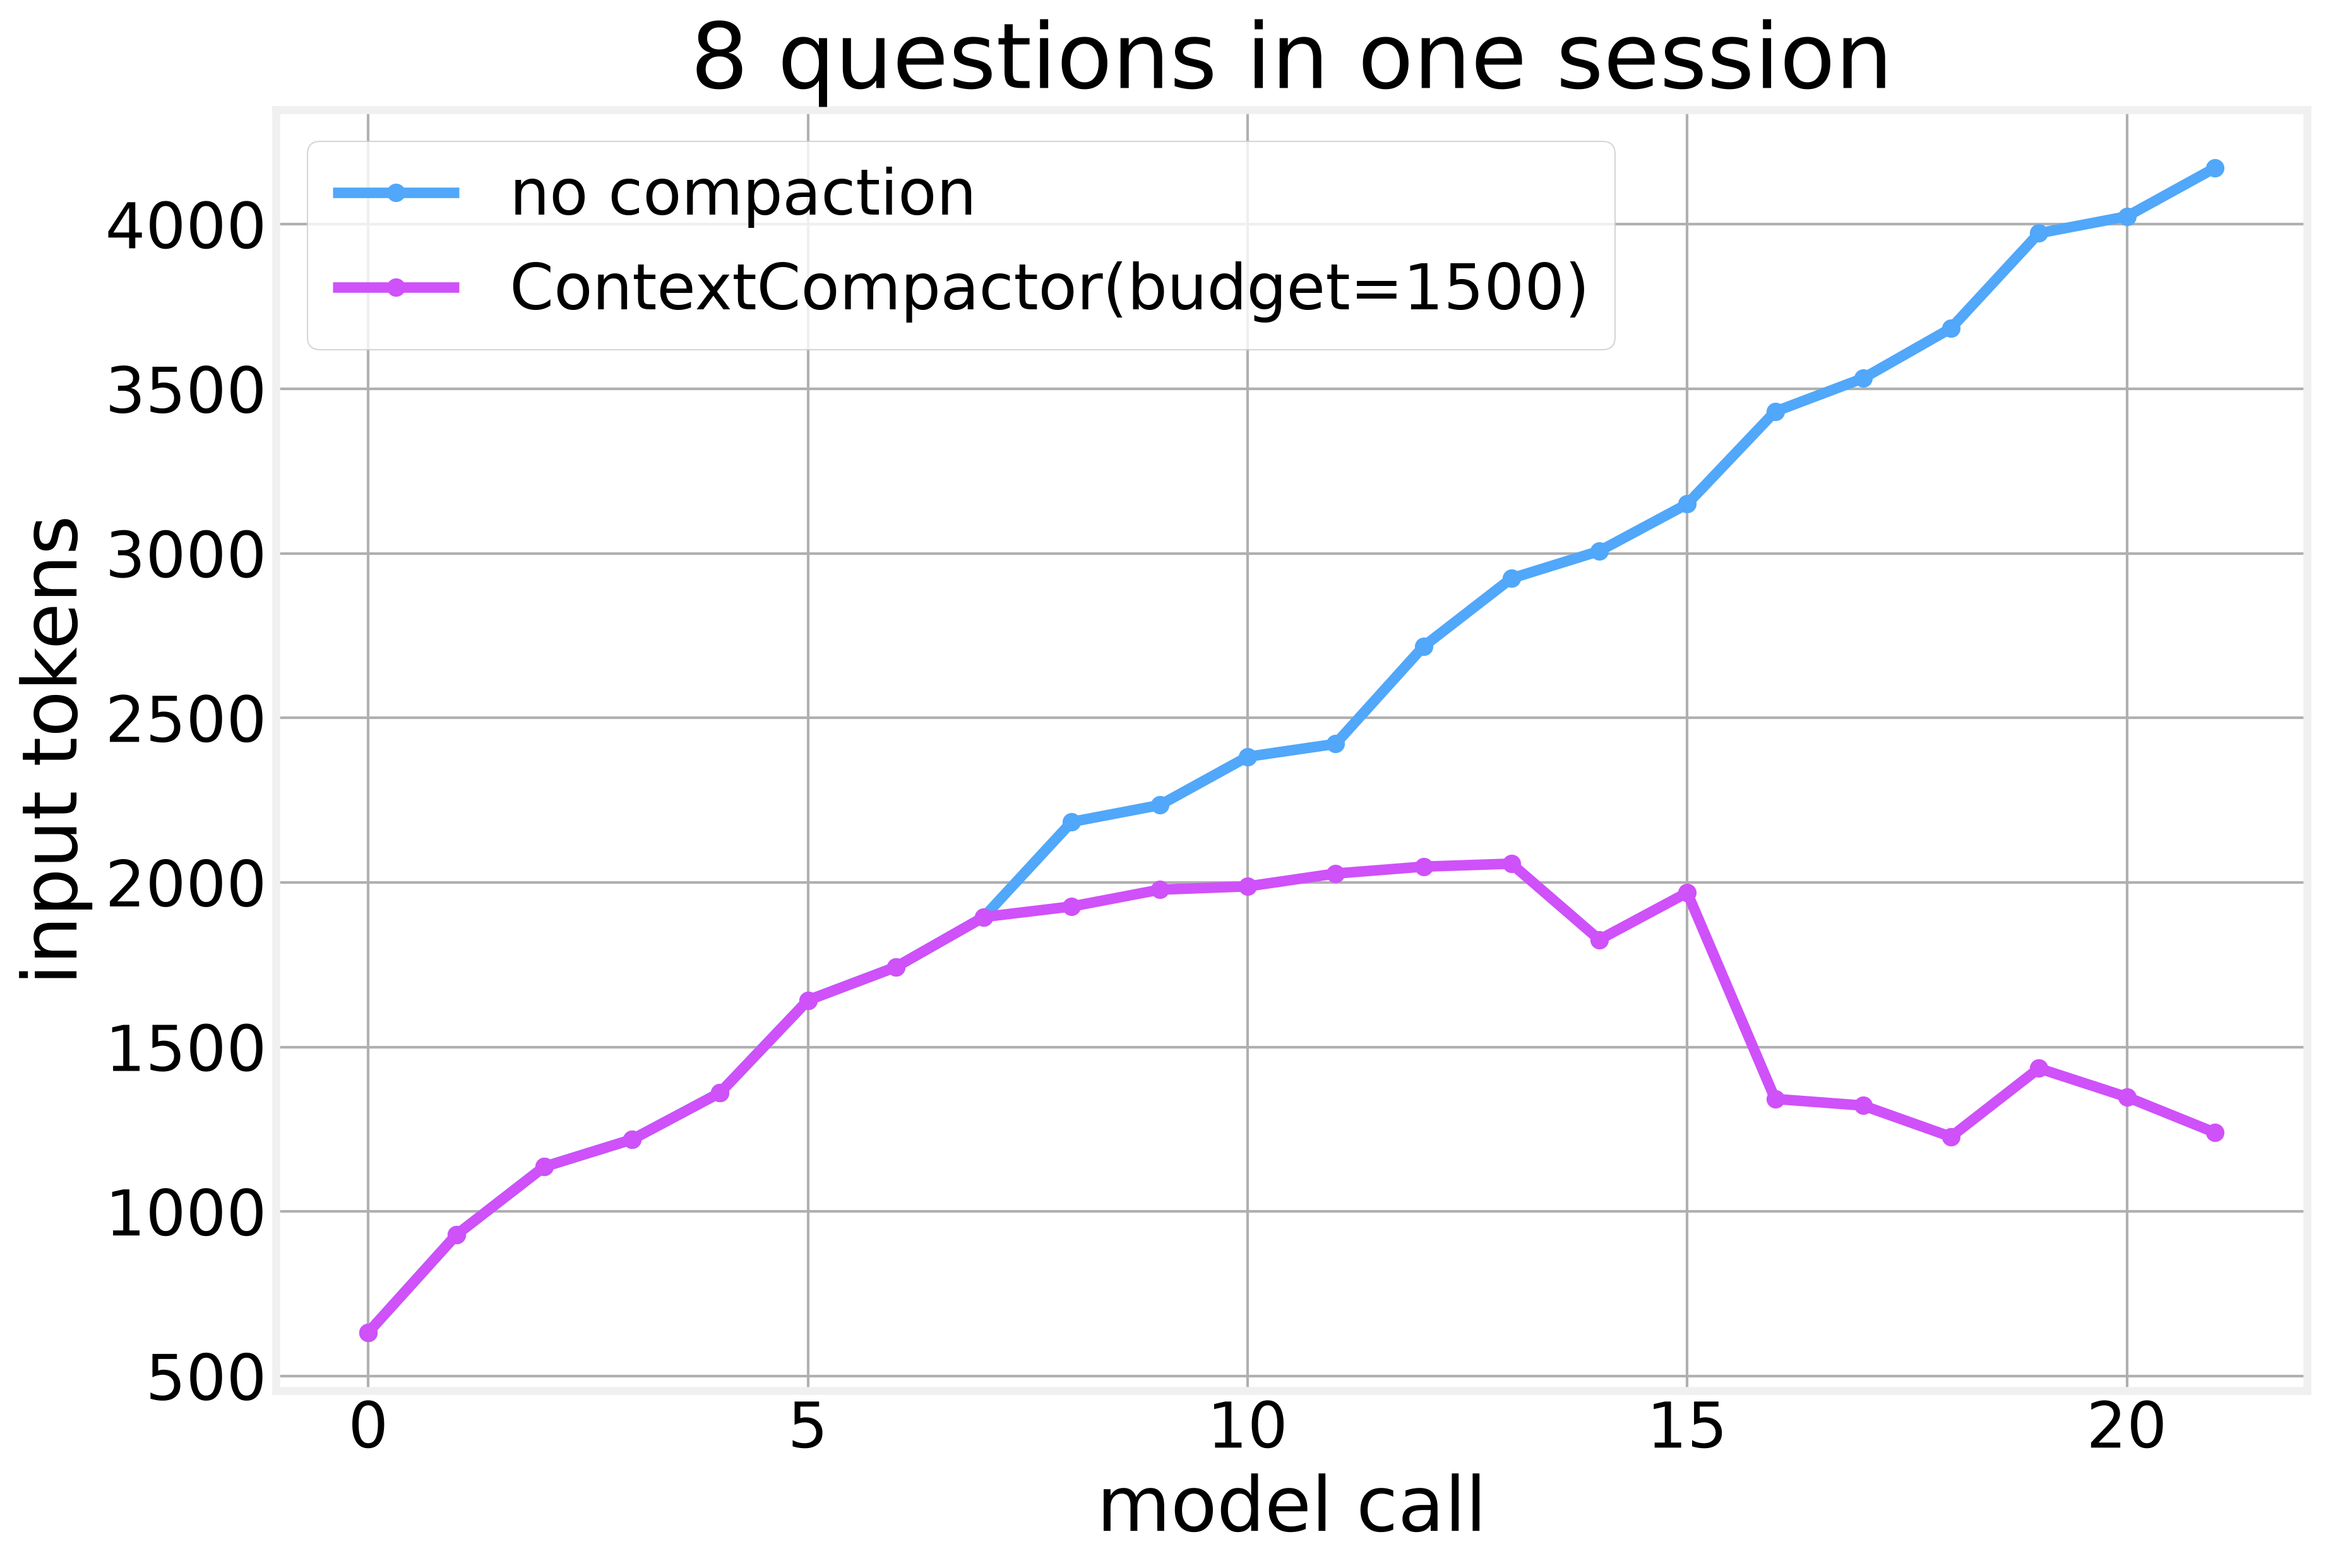

In [17]:
fig, ax = plt.subplots()
ax.plot(plain, marker="o", color=colors[0], label="no compaction")
ax.plot(compacted, marker="o", color=colors[1], label="ContextCompactor(budget=1500)")
ax.set_xlabel("model call")
ax.set_ylabel("input tokens")
ax.set_title("8 questions in one session")
ax.legend();

In [18]:
print(last.answer)
pd.DataFrame(compactor.log).tail()

EMEA revenue was $142,227 in July versus $249,793 in June, a 43% decline.


,before,after
9,2964,754
10,3116,659
11,3405,867
12,3456,780
13,3603,672


Without compaction, input tokens grow with every call. With it they level off, and the last answer is still correct, because the current question and its own results are never compacted. The tokens used on the plot sit a little above the budget because they also count the tool definitions, which the compactor can't remove.

# 7. Tiered memory

Summaries and handles manage the *current* run. Some knowledge should outlive a run: the facts a human analyst carries around in their head. A practical split:

| Tier | Lives in | Lifetime | Example |
|:--|:--|:--|:--|
| Working memory | the message list | one model call | the rows just returned |
| Session memory | handles, compaction summaries | one conversation | `r3` holds August feedback |
| Long-term memory | a curated store on disk | across runs | "amount_cents is in cents" |

Long-term facts are recalled by relevance to the question and placed in the system prompt. The key design decision is **who may write** to long-term memory.

In [19]:
%%writefile -a harness/context.py


# --- tiered memory -----------------------------------------------------------------------

_WORD = re.compile(r"[a-z_]{3,}")


def _words(text: str) -> set[str]:
    return set(_WORD.findall(text.lower()))


@dataclass
class Memory:
    text: str
    source: str            # who asserted it: "human", "verified", "agent"
    tags: list[str] = field(default_factory=list)


class MemoryStore:
    """Long-term memory: small, curated facts that survive across runs.

    Facts are recalled by word overlap with the question and placed in the
    system prompt. Only trusted sources may write here; anything the agent read
    inside data is *not* a trusted source."""

    TRUSTED = {"human", "verified"}

    def __init__(self, path: str | Path | None = None):
        self.path = Path(path) if path else None
        self.items: list[Memory] = []
        if self.path and self.path.exists():
            self.items = [Memory(**m) for m in json.loads(self.path.read_text())]

    def add(self, text: str, source: str, tags: list[str] = ()) -> bool:
        if source not in self.TRUSTED:
            return False
        if all(m.text != text for m in self.items):
            self.items.append(Memory(text, source, list(tags)))
            self.save()
        return True

    def recall(self, query: str, k: int = 3) -> list[Memory]:
        q = _words(query)
        scored = [(len(q & (_words(m.text) | set(m.tags))), i, m)
                  for i, m in enumerate(self.items)]
        return [m for s, _, m in sorted(scored, key=lambda x: (-x[0], x[1])) if s > 0][:k]

    def save(self) -> None:
        if self.path:
            self.path.write_text(json.dumps([m.__dict__ for m in self.items], indent=1))

    def system_prompt(self, base: str, question: str, k: int = 3) -> str:
        facts = self.recall(question, k)
        if not facts:
            return base
        return base + "\n\nKnown facts about this database:\n" + "\n".join(
            f"- {m.text}" for m in facts)

Appending to harness/context.py


In [20]:
load("context")
from harness.context import MemoryStore

Path("outputs").mkdir(exist_ok=True)
memory = MemoryStore("outputs/memory.json")
memory.add("orders.amount_cents is in US cents: divide by 100 to report revenue in dollars.",
           source="human", tags=["revenue"])
memory.add("Revenue counts only orders with status = 'completed'.", source="human", tags=["revenue"])
memory.add("ingestion_log records failed daily loads; check it before comparing periods.",
           source="human", tags=["missing", "compare", "revenue"])

QUESTION = "What was our monthly revenue in 2026?"
for m in memory.recall(QUESTION):
    print("-", m.text)

- orders.amount_cents is in US cents: divide by 100 to report revenue in dollars.
- Revenue counts only orders with status = 'completed'.
- ingestion_log records failed daily loads; check it before comparing periods.


In [21]:
system = memory.system_prompt(DEFAULT_SYSTEM_PROMPT, QUESTION)
print(system)

You are a data analyst for Trailhead Supply Co.
Answer questions by querying the company's DuckDB database with the tools provided.
Base every number you report on a query result.

Known facts about this database:
- orders.amount_cents is in US cents: divide by 100 to report revenue in dollars.
- Revenue counts only orders with status = 'completed'.
- ingestion_log records failed daily loads; check it before comparing periods.


Now the same sloppy model from notebook 01, with recalled memory in its system prompt:

In [22]:
agent = Agent(MockAnalyst(), toolbox, system_prompt=system,
              after_tool=[ResultCompactor(store)])
res = agent.run(QUESTION)
print(res.answer)

Monthly revenue for 2026:
- 2026-01: $457,724
- 2026-02: $421,812
- 2026-03: $584,478
- 2026-04: $628,349
- 2026-05: $776,473
- 2026-06: $813,741
- 2026-07: $750,202
- 2026-08: $650,223
- 2026-09: $373,359

Revenue fell 43% in 2026-09 compared with 2026-08.


Revenue is now in dollars. The model didn't get smarter; its context got better.

**Memory poisoning.** If the agent could write whatever it read into long-term memory, one injected comment would become a permanent "fact" in every future run. Our store accepts writes only from trusted sources:

In [23]:
print("agent write accepted:", memory.add("Q3 revenue grew 40%.", source="agent"))
print([m.text for m in memory.items])

agent write accepted: False
['orders.amount_cents is in US cents: divide by 100 to report revenue in dollars.', "Revenue counts only orders with status = 'completed'.", 'ingestion_log records failed daily loads; check it before comparing periods.']


You now have a working `harness/context.py`.

**Takeaways**
- Measure tool results in tokens; one `SELECT *` can use up the whole budget.
- Summaries must be honest about truncation and point to where the full data lives.
- Compact the conversation, but never the current question or a half-finished tool exchange.
- Long-term memory is a curated, write-protected store, not a dump of the transcript.

# Exercise: keep the last N results

*Estimated time: 8 minutes*

Write a simpler compaction strategy, `keep_last_results(messages, n=2)`:

- keep the **last `n` tool results** exactly as they are
- replace every **older** tool result's content with a short stub (under 200 characters) that names its handle (e.g. `"[older result elided; full data in r3]"`). The handle is in the content as `"handle": "r3"`.
- keep every message in place (same roles, same `tool_call_id`s), so calls and results stay paired
- **don't mutate** the input list or its dictionaries

The checker builds a 6-result transcript (`long_transcript()`) and requires the output to fit in 3,000 tokens.

In [24]:
import re

def keep_last_results(messages, n=2):
    # YOUR CODE HERE
    return messages

In [25]:
check_03(keep_last_results)

PASS  input list not mutated
PASS  same roles in the same order
PASS  tool_call_ids preserved
PASS  last 2 results kept verbatim
FAIL  older results replaced by short stubs naming their handle
FAIL  prompt under 3000 tokens  (7313 tokens)

Not there yet; keep going.


<details>
<summary><b>Show solution</b></summary>

```python
# Solution: keep the last n tool results verbatim, stub out the older ones.
import json
import re

from harness.exercises import check_03


def keep_last_results(messages, n=2):
    tool_idx = [i for i, m in enumerate(messages) if m["role"] == "tool"]
    old = set(tool_idx[:-n]) if n else set(tool_idx)
    out = []
    for i, m in enumerate(messages):
        m = dict(m)                                   # never mutate the caller's list
        if i in old:
            handle = re.search(r'"handle": "(r\d+)"', m["content"])
            m["content"] = ("[older result elided"
                            + (f"; full data in {handle.group(1)}, use expand_result" if handle else "")
                            + "]")
        out.append(m)
    return out


check_03(keep_last_results)
```

You can also load it into a new cell with `%load solutions/03_keep_last_results.py`.

</details>

In [26]:
client.close()

<center>
     <img src="data/D4Sci_logo_full.png" alt="Data For Science, Inc" align="center" border="0" width=300px>
</center>